In [3]:
import os
from pathlib import Path
import sys

prefix = Path(sys.prefix).resolve()
for _var in ("PROJ_LIB", "PROJ_DATA"):
    _val = os.environ.get(_var)
    if _val:
        try:
            if not Path(_val).resolve().is_relative_to(prefix):
                os.environ.pop(_var, None)
        except OSError:
            os.environ.pop(_var, None)
os.environ.setdefault("AWS_NO_SIGN_REQUEST", "YES")

import calendar
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
from pystac_client import Client
import rasterio
from rasterio.enums import Resampling
from rasterio.features import geometry_mask, rasterize
from rasterio.mask import mask
from rasterio.vrt import WarpedVRT
from shapely.geometry import shape
from shapely.ops import unary_union

BASE_DIR = Path("field_classification") if Path("field_classification").exists() else Path(".")
OUT_DIR = BASE_DIR / "enter_data"

AOI_CONFIGS = [
    {"name": "aoi_1", "boundary": BASE_DIR / "boundary.geojson", "label": BASE_DIR / "label_2.geojson"},
    {"name": "aoi_3", "boundary": BASE_DIR / "boundary_3.geojson", "label": BASE_DIR / "label_3.geojson"},
]
YEARS = (2024, 2025)
MONTHS = tuple(range(3, 11))  # marzec .. pazdziernik
BAND_NAMES = ("RED", "GREEN", "BLUE", "NIR", "SWIR16", "SWIR22", "NDVI", "NDWI", "DOY_SIN", "DOY_COS")

In [4]:
_REQUIRED_ASSETS = ("red", "green", "blue", "nir", "swir16", "swir22")
_SCL_CLOUD_CLASSES = (3, 8, 9, 10)
CLASS_MAP = {"inne": 0, "inny": 0, "pole": 1}
BOUNDARY_CLASS = 2
IGNORE_VALUE = 255


def _scale_s2_reflectance(arr: np.ndarray, asset, src_nodata=None) -> np.ndarray:
    """Przeskaluj piksele Sentinel-2 L2A do odbicia powierzchniowego [0, 1] z uwzglednieniem offsetu."""
    out = arr.astype(np.float32, copy=True)
    out[out == 0] = np.nan
    if src_nodata is not None and np.isfinite(src_nodata):
        out[out == np.float32(src_nodata)] = np.nan

    rb = (getattr(asset, "extra_fields", None) or {}).get("raster:bands") or []
    info = rb[0] if rb and isinstance(rb[0], dict) else {}
    if "nodata" in info and info["nodata"] is not None and np.isfinite(info["nodata"]):
        out[out == np.float32(info["nodata"])] = np.nan

    if "scale" in info or "offset" in info:
        out = out * float(info.get("scale", 1.0)) + float(info.get("offset", 0.0))
    elif np.any(np.isfinite(out)) and float(np.nanmax(out)) > 1.5:
        out = out * 0.0001

    return np.clip(out, 0.0, 1.0).astype(np.float32)


def _cyclic_doy(dt, year: int) -> tuple[int, float, float]:
    doy = int(dt.timetuple().tm_yday)
    days_in_year = 366 if calendar.isleap(year) else 365
    angle = 2.0 * np.pi * doy / days_in_year
    return doy, float(np.sin(angle)), float(np.cos(angle))


def search_monthly_sentinel2_metadata(
    boundary_file: str | Path,
    year: int = 2024,
    months: tuple[int, ...] = tuple(range(3, 11)),
    max_cc: float = 30.0,
    fallback_max_cc: float = 80.0,
    min_coverage: float = 0.98,
    min_candidates_per_month: int = 1,
    stac_url: str = "https://earth-search.aws.element84.com/v1",
) -> tuple[pd.DataFrame, dict[int, list]]:
    """Etap 1: Wyszukaj metadane STAC Sentinel-2 L2A i uszereguj kandydatow wg najnizszego CC."""
    boundary = gpd.read_file(boundary_file)
    boundary = boundary[boundary.geometry.notna() & ~boundary.geometry.is_empty].copy()
    if boundary.empty:
        raise ValueError(f"Brak poprawnych geometrii w pliku granic: {boundary_file}")

    boundary_wgs84 = boundary.to_crs("EPSG:4326")
    boundary_union = unary_union(boundary_wgs84.geometry)
    search_bbox = [float(v) for v in boundary_wgs84.total_bounds]
    client = Client.open(stac_url)

    monthly_candidates: dict[int, list[dict]] = {m: [] for m in months}
    seen_ids: set[str] = set()

    def _collect(month_subset: tuple[int, ...], cc_limit: float) -> None:
        m_min, m_max = min(month_subset), max(month_subset)
        last_day = calendar.monthrange(year, m_max)[1]
        search = client.search(
            collections=["sentinel-2-l2a"],
            bbox=search_bbox,
            datetime=f"{year}-{m_min:02d}-01/{year}-{m_max:02d}-{last_day:02d}",
            query={"eo:cloud_cover": {"lt": cc_limit}},
        )
        for item in search.items():
            if item.id in seen_ids or item.datetime is None:
                continue
            dt = item.datetime
            if dt.year != year or dt.month not in month_subset:
                continue
            if not all(name in item.assets for name in _REQUIRED_ASSETS):
                continue

            if item.geometry is not None and boundary_union.area > 0:
                cov = float(shape(item.geometry).intersection(boundary_union).area / boundary_union.area)
            else:
                cov = 1.0
            if cov <= 0.0:
                continue

            seen_ids.add(item.id)
            cc = float(item.properties.get("eo:cloud_cover", 100.0))
            monthly_candidates[dt.month].append({
                "item": item, "month": dt.month, "date": dt.strftime("%Y-%m-%d"), "dt": dt,
                "cloud_cover": cc, "coverage": cov,
                "mgrs_tile": item.properties.get("grid:code") or item.properties.get("s2:mgrs_tile") or "",
            })

    _collect(tuple(months), max_cc)
    need_more = tuple(
        m for m in months
        if len({c["date"] for c in monthly_candidates[m] if c["coverage"] >= min_coverage}) < min_candidates_per_month
    )
    if need_more and fallback_max_cc > max_cc:
        _collect(need_more, fallback_max_cc)

    ranked_candidates: dict[int, list] = {}
    meta_rows: list[dict] = []
    for m in months:
        cands = sorted(monthly_candidates[m], key=lambda c: (c["coverage"] < min_coverage, c["cloud_cover"], -c["coverage"], c["dt"]))
        ranked_candidates[m] = [c["item"] for c in cands]
        if cands:
            best = cands[0]
            doy, doy_sin, doy_cos = _cyclic_doy(best["dt"], year)
            meta_rows.append({
                "month": m, "date": best["date"], "doy": doy,
                "doy_sin": round(doy_sin, 6), "doy_cos": round(doy_cos, 6),
                "cloud_cover": round(best["cloud_cover"], 2),
                "coverage_pct": round(100.0 * best["coverage"], 2),
                "mgrs_tile": best["mgrs_tile"], "scene_id": best["item"].id, "n_candidates": len(cands),
            })
        else:
            meta_rows.append({
                "month": m, "date": None, "doy": None, "doy_sin": np.nan, "doy_cos": np.nan,
                "cloud_cover": np.nan, "coverage_pct": 0.0, "mgrs_tile": "", "scene_id": None, "n_candidates": 0,
            })

    return pd.DataFrame(meta_rows), ranked_candidates


def _build_ref_grid_from_asset(boundary: gpd.GeoDataFrame, asset) -> dict:
    with rasterio.open(asset.href) as src:
        shapes_proj = [geom.__geo_interface__ for geom in boundary.to_crs(src.crs).geometry]
        clipped, tf = mask(src, shapes_proj, crop=True, nodata=0)
        h, w = clipped.shape[1], clipped.shape[2]
        in_mask = geometry_mask(shapes_proj, out_shape=(h, w), transform=tf, invert=True)
        if not np.any(in_mask):
            in_mask = geometry_mask(shapes_proj, out_shape=(h, w), transform=tf, invert=True, all_touched=True)
        return {"crs": src.crs, "transform": tf, "height": h, "width": w, "in_mask": in_mask}


def _grid_from_ref_raster(boundary: gpd.GeoDataFrame, ref_raster_path: str | Path) -> dict:
    with rasterio.open(ref_raster_path) as src:
        shapes_proj = [geom.__geo_interface__ for geom in boundary.to_crs(src.crs).geometry]
        in_mask = geometry_mask(shapes_proj, out_shape=(src.height, src.width), transform=src.transform, invert=True)
        if not np.any(in_mask):
            in_mask = geometry_mask(shapes_proj, out_shape=(src.height, src.width), transform=src.transform, invert=True, all_touched=True)
        return {"crs": src.crs, "transform": src.transform, "height": src.height, "width": src.width, "in_mask": in_mask}


def _read_warped_band(asset, grid: dict, resampling: Resampling, is_scl: bool = False) -> np.ndarray:
    with rasterio.open(asset.href) as src:
        with WarpedVRT(
            src, crs=grid["crs"], transform=grid["transform"],
            width=grid["width"], height=grid["height"], resampling=resampling,
        ) as vrt:
            arr = vrt.read(1)
            nodata = src.nodata if src.nodata is not None else vrt.nodata
    return arr if is_scl else _scale_s2_reflectance(arr, asset, src_nodata=nodata)


def _prepare_scene_stack(item, boundary: gpd.GeoDataFrame, ref_grid: dict | None, year: int, mask_clouds: bool):
    grid = ref_grid if ref_grid is not None else _build_ref_grid_from_asset(boundary, item.assets["red"])
    in_mask = grid["in_mask"]
    total_px = int(np.sum(in_mask))
    if total_px == 0:
        raise ValueError("Maska boundary na siatce 10 m jest pusta.")

    bands = {b: _read_warped_band(item.assets[b], grid, Resampling.bilinear) for b in _REQUIRED_ASSETS}
    scl_cloud = np.zeros(in_mask.shape, dtype=bool)
    if "scl" in item.assets:
        scl_arr = _read_warped_band(item.assets["scl"], grid, Resampling.nearest, is_scl=True)
        scl_cloud = np.isin(scl_arr, _SCL_CLOUD_CLASSES)

    red, green, blue, nir, swir16, swir22 = (bands[b] for b in _REQUIRED_ASSETS)
    with np.errstate(divide="ignore", invalid="ignore"):
        denom_ndvi = nir + red
        ndvi = np.where(np.isfinite(denom_ndvi) & (np.abs(denom_ndvi) > 1e-6), (nir - red) / denom_ndvi, np.nan).astype(np.float32)
        denom_ndwi = green + nir
        ndwi = np.where(np.isfinite(denom_ndwi) & (np.abs(denom_ndwi) > 1e-6), (green - nir) / denom_ndwi, np.nan).astype(np.float32)
    ndvi, ndwi = np.clip(ndvi, -1.0, 1.0), np.clip(ndwi, -1.0, 1.0)

    valid_spectral = (
        np.isfinite(red) & np.isfinite(green) & np.isfinite(blue)
        & np.isfinite(nir) & np.isfinite(swir16) & np.isfinite(swir22)
        & np.isfinite(ndvi) & np.isfinite(ndwi)
    )
    missing_ratio = float(np.sum(in_mask & (~valid_spectral | scl_cloud))) / total_px

    clear_mask = in_mask & ~(scl_cloud if mask_clouds else False)
    spectral_layers = [np.where(clear_mask, arr, np.nan).astype(np.float32) for arr in (red, green, blue, nir, swir16, swir22, ndvi, ndwi)]

    doy, doy_sin, doy_cos = _cyclic_doy(item.datetime, year)
    sin_layer = np.where(in_mask, np.float32(doy_sin), np.nan).astype(np.float32)
    cos_layer = np.where(in_mask, np.float32(doy_cos), np.nan).astype(np.float32)

    stack = np.stack([*spectral_layers, sin_layer, cos_layer], axis=0).astype(np.float32)
    return stack, grid, missing_ratio, doy, doy_sin, doy_cos


def download_clip_monthly_sentinel2(
    boundary_file: str | Path,
    out_dir: str | Path,
    year: int = 2024,
    months: tuple[int, ...] = tuple(range(3, 11)),
    n_per_month: int = 1,
    max_cc: float = 30.0,
    fallback_max_cc: float = 80.0,
    max_missing_ratio: float = 0.20,
    mask_clouds: bool = True,
    overwrite: bool = False,
    ref_raster_path: str | Path | None = None,
    stac_url: str = "https://earth-search.aws.element84.com/v1",
) -> pd.DataFrame:
    """Wyszukaj metadane, pobierz do n_per_month scen per miesiac (III-X) i zapisz stosy 10-kanalowe."""
    out_path = Path(out_dir)
    out_path.mkdir(parents=True, exist_ok=True)

    boundary = gpd.read_file(boundary_file)
    boundary = boundary[boundary.geometry.notna() & ~boundary.geometry.is_empty].copy()
    if boundary.empty:
        raise ValueError(f"Brak poprawnych geometrii w pliku granic: {boundary_file}")

    print(f"[1/2] Wyszukiwanie metadanych STAC ({out_path.name}, rok {year}, cel={n_per_month}/mies.)...")
    meta_df, monthly_candidates = search_monthly_sentinel2_metadata(
        boundary_file=boundary_file, year=year, months=months,
        max_cc=max_cc, fallback_max_cc=fallback_max_cc,
        min_candidates_per_month=n_per_month, stac_url=stac_url,
    )
    print(f"  Miesiace z kandydatami: {int((meta_df['n_candidates'] > 0).sum())}/{len(months)}")

    ref_grid: dict | None = _grid_from_ref_raster(boundary, ref_raster_path) if (ref_raster_path is not None and Path(ref_raster_path).exists()) else None
    rows: list[dict] = []

    print(f"[2/2] Pobieranie i przycinanie ({out_path.name}, rok {year})...")
    for m in months:
        saved_for_m = 0
        saved_dates: set[str] = set()
        existing = sorted(out_path.glob(f"s2_l2a_{year}_{m:02d}_*.tif"))

        if not overwrite and existing:
            for tif_path in existing:
                with rasterio.open(tif_path) as src:
                    if src.count != len(BAND_NAMES):
                        continue
                    if ref_grid is None:
                        ref_grid = _grid_from_ref_raster(boundary, tif_path)
                    band7 = src.read(7)
                    in_m = ref_grid["in_mask"] if ref_grid["crs"] == src.crs and band7.shape == ref_grid["in_mask"].shape else np.isfinite(band7)
                    valid_pct = round(100.0 * float(np.sum(in_m & np.isfinite(band7))) / max(1, int(np.sum(in_m))), 2)
                scene_date = tif_path.stem.rsplit("_", 1)[-1]
                saved_dates.add(scene_date)
                saved_for_m += 1
                rows.append({"month": m, "date": scene_date, "scene_id": "cached", "cloud_cover": np.nan, "valid_pct": valid_pct, "status": "cached", "file_path": str(tif_path)})
                print(f"  Miesiac {m:02d} (cache {saved_for_m}/{n_per_month}): {tif_path.name}")
                if saved_for_m >= n_per_month:
                    break

        if saved_for_m >= n_per_month:
            continue

        cands = monthly_candidates.get(m, [])
        if not cands and saved_for_m == 0:
            print(f"  Miesiac {m:02d}: brak scen spelniajacych kryteria.")
            rows.append({"month": m, "date": None, "scene_id": None, "cloud_cover": np.nan, "valid_pct": 0.0, "status": "missing", "file_path": None})
            continue

        best_fallback = None
        for item in cands:
            if saved_for_m >= n_per_month:
                break
            scene_date = item.datetime.strftime("%Y-%m-%d")
            if scene_date in saved_dates:
                continue
            try:
                stack, grid, miss_ratio, doy, doy_sin, doy_cos = _prepare_scene_stack(item, boundary, ref_grid, year=year, mask_clouds=mask_clouds)
            except Exception as exc:
                print(f"  Miesiac {m:02d}: blad sceny {item.id} ({exc}), probuje kolejna.")
                continue

            entry = (miss_ratio, item, stack, grid, doy, doy_sin, doy_cos)
            if best_fallback is None or miss_ratio < best_fallback[0]:
                best_fallback = entry

            if miss_ratio <= max_missing_ratio:
                if ref_grid is None:
                    ref_grid = grid
                out_file = out_path / f"s2_l2a_{year}_{m:02d}_{scene_date}.tif"
                profile = {
                    "driver": "GTiff", "height": grid["height"], "width": grid["width"],
                    "count": len(BAND_NAMES), "dtype": "float32", "crs": grid["crs"],
                    "transform": grid["transform"], "nodata": np.nan, "compress": "deflate",
                }
                with rasterio.open(out_file, "w", **profile) as dst:
                    dst.write(stack)
                    for idx, bname in enumerate(BAND_NAMES, start=1):
                        dst.set_band_description(idx, bname)
                saved_dates.add(scene_date)
                saved_for_m += 1
                cc = float(item.properties.get("eo:cloud_cover", np.nan))
                valid_pct = round(100.0 * (1.0 - miss_ratio), 2)
                print(f"  Miesiac {m:02d} ({saved_for_m}/{n_per_month}, {scene_date}): {item.id} | CC={cc:.1f}% | pokrycie={valid_pct:.1f}% -> {out_file.name}")
                rows.append({
                    "month": m, "date": scene_date, "doy": doy, "doy_sin": round(doy_sin, 6), "doy_cos": round(doy_cos, 6),
                    "scene_id": item.id, "cloud_cover": round(cc, 2), "valid_pct": valid_pct, "status": "ok", "file_path": str(out_file),
                })

        if saved_for_m == 0 and best_fallback is not None:
            miss_ratio, item, stack, grid, doy, doy_sin, doy_cos = best_fallback
            if ref_grid is None:
                ref_grid = grid
            scene_date = item.datetime.strftime("%Y-%m-%d")
            out_file = out_path / f"s2_l2a_{year}_{m:02d}_{scene_date}.tif"
            profile = {
                "driver": "GTiff", "height": grid["height"], "width": grid["width"],
                "count": len(BAND_NAMES), "dtype": "float32", "crs": grid["crs"],
                "transform": grid["transform"], "nodata": np.nan, "compress": "deflate",
            }
            with rasterio.open(out_file, "w", **profile) as dst:
                dst.write(stack)
                for idx, bname in enumerate(BAND_NAMES, start=1):
                    dst.set_band_description(idx, bname)
            cc = float(item.properties.get("eo:cloud_cover", np.nan))
            valid_pct = round(100.0 * (1.0 - miss_ratio), 2)
            print(f"  Miesiac {m:02d} (fallback, {scene_date}): {item.id} | CC={cc:.1f}% | pokrycie={valid_pct:.1f}% -> {out_file.name}")
            rows.append({
                "month": m, "date": scene_date, "doy": doy, "doy_sin": round(doy_sin, 6), "doy_cos": round(doy_cos, 6),
                "scene_id": item.id, "cloud_cover": round(cc, 2), "valid_pct": valid_pct, "status": "fallback_cloudy", "file_path": str(out_file),
            })

    results_df = pd.DataFrame(rows)
    results_df.to_csv(out_path / f"metadata_{year}.csv", index=False)
    return results_df


def rasterize_pixel_labels(
    label_file: str | Path,
    ref_raster_path: str | Path,
    boundary_file: str | Path | None = None,
    out_path: str | Path | None = None,
    class_col: str = "class",
    class_map: dict[str, int] = CLASS_MAP,
    ignore_value: int = IGNORE_VALUE,
    add_field_boundaries: bool = True,
    boundary_class: int = BOUNDARY_CLASS,
    all_touched: bool = False,
) -> tuple[np.ndarray, dict]:
    """Przypisz etykiety: 0=inne, 1=pole, 2=granica_pola (linia 1 px na styku), 255=ignoruj."""
    with rasterio.open(ref_raster_path) as src:
        crs, transform, height, width = src.crs, src.transform, src.height, src.width
        ref_band = src.read(1) if boundary_file is None else None

    if boundary_file is not None:
        b_gdf = gpd.read_file(boundary_file)
        b_gdf = b_gdf[b_gdf.geometry.notna() & ~b_gdf.geometry.is_empty].to_crs(crs)
        b_geoms = [g.__geo_interface__ for g in b_gdf.geometry]
        in_mask = geometry_mask(b_geoms, out_shape=(height, width), transform=transform, invert=True)
        if not np.any(in_mask):
            in_mask = geometry_mask(b_geoms, out_shape=(height, width), transform=transform, invert=True, all_touched=True)
    else:
        in_mask = np.isfinite(ref_band)

    gdf = gpd.read_file(label_file)
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
    gdf["geometry"] = gdf.geometry.apply(lambda g: g if g.is_valid else g.buffer(0))
    gdf = gdf.to_crs(crs)

    norm_cls = gdf[class_col].astype(str).str.strip().str.lower()
    gdf["_cls_id"] = norm_cls.map(class_map)
    unmapped = sorted(set(norm_cls[gdf["_cls_id"].isna()]))
    if unmapped:
        print(f"Uwaga — pominieto nieznane klasy w '{class_col}': {unmapped}")
    gdf = gdf[gdf["_cls_id"].notna()].copy()
    gdf["_cls_id"] = gdf["_cls_id"].astype(int)

    gdf = gdf.sort_values("_cls_id", ascending=False).reset_index(drop=True)
    gdf["_poly_id"] = np.arange(1, len(gdf) + 1, dtype=np.int32)

    shapes_cls = [(geom, int(val)) for geom, val in zip(gdf.geometry, gdf["_cls_id"])]
    label_mask = (
        rasterize(shapes_cls, out_shape=(height, width), transform=transform, fill=ignore_value, dtype="uint8", all_touched=all_touched)
        if shapes_cls
        else np.full((height, width), ignore_value, dtype=np.uint8)
    )

    if add_field_boundaries and shapes_cls:
        shapes_pid = [(geom, int(pid)) for geom, pid in zip(gdf.geometry, gdf["_poly_id"])]
        poly_id = rasterize(shapes_pid, out_shape=(height, width), transform=transform, fill=0, dtype="int32", all_touched=all_touched)
        b_mask = np.zeros((height, width), dtype=bool)
        h_diff = (poly_id[:, :-1] > 0) & (poly_id[:, 1:] > 0) & in_mask[:, :-1] & in_mask[:, 1:] & (poly_id[:, :-1] != poly_id[:, 1:]) & ((label_mask[:, :-1] == 1) | (label_mask[:, 1:] == 1))
        b_mask[:, :-1] |= h_diff
        v_diff = (poly_id[:-1, :] > 0) & (poly_id[1:, :] > 0) & in_mask[:-1, :] & in_mask[1:, :] & (poly_id[:-1, :] != poly_id[1:, :]) & ((label_mask[:-1, :] == 1) | (label_mask[1:, :] == 1))
        b_mask[:-1, :] |= v_diff
        label_mask[b_mask] = boundary_class

    label_mask[~in_mask] = ignore_value

    meta = {"driver": "GTiff", "height": height, "width": width, "count": 1, "dtype": "uint8", "crs": crs, "transform": transform, "nodata": ignore_value, "compress": "deflate"}
    if out_path is not None:
        out_p = Path(out_path)
        out_p.parent.mkdir(parents=True, exist_ok=True)
        with rasterio.open(out_p, "w", **meta) as dst:
            dst.write(label_mask, 1)
            dst.set_band_description(1, "LABEL_MASK")
    return label_mask, meta

In [5]:
# Etap 1 + 2: Pobranie do 4 scen/mies. dla 2024 (Train) i 1 sceny/mies. dla 2025 (Val/Test) oraz rasteryzacja masek z granica_pola
all_runs = []
for cfg in AOI_CONFIGS:
    aoi_dir = OUT_DIR / cfg["name"]
    df_2024 = download_clip_monthly_sentinel2(
        boundary_file=cfg["boundary"],
        out_dir=aoi_dir,
        year=2024,
        months=MONTHS,
        n_per_month=4,
        max_cc=30.0,
        fallback_max_cc=80.0,
        max_missing_ratio=0.20,
        mask_clouds=True,
        overwrite=False,
    )
    tifs_2024 = sorted(aoi_dir.glob("s2_l2a_2024_*.tif"))
    ref_tif = tifs_2024[0] if tifs_2024 else None

    df_2025 = download_clip_monthly_sentinel2(
        boundary_file=cfg["boundary"],
        out_dir=aoi_dir,
        year=2025,
        months=MONTHS,
        n_per_month=1,
        max_cc=30.0,
        fallback_max_cc=80.0,
        max_missing_ratio=0.20,
        mask_clouds=True,
        overwrite=False,
        ref_raster_path=ref_tif,
    )

    if ref_tif is None:
        ref_tif = sorted(aoi_dir.glob("s2_l2a_*.tif"))[0]
    label_mask, _ = rasterize_pixel_labels(
        label_file=cfg["label"],
        ref_raster_path=ref_tif,
        boundary_file=cfg["boundary"],
        out_path=aoi_dir / "label_mask.tif",
        add_field_boundaries=True,
    )
    print(f"[{cfg['name']}] Zapisano label_mask.tif | shape={label_mask.shape} | inne={int((label_mask == 0).sum())}, pole={int((label_mask == 1).sum())}, granica={int((label_mask == 2).sum())}")
    for yr, df_yr in ((2024, df_2024), (2025, df_2025)):
        df_yr = df_yr.copy()
        df_yr.insert(0, "year", yr)
        df_yr.insert(0, "aoi", cfg["name"])
        all_runs.append(df_yr)

summary_df = pd.concat(all_runs, ignore_index=True)
summary_df

[1/2] Wyszukiwanie metadanych STAC (aoi_1, rok 2024, cel=4/mies.)...
  Miesiace z kandydatami: 8/8
[2/2] Pobieranie i przycinanie (aoi_1, rok 2024)...
  Miesiac 03 (cache 1/4): s2_l2a_2024_03_2024-03-07.tif
  Miesiac 03 (cache 2/4): s2_l2a_2024_03_2024-03-09.tif
  Miesiac 04 (cache 1/4): s2_l2a_2024_04_2024-04-13.tif
  Miesiac 04 (cache 2/4): s2_l2a_2024_04_2024-04-26.tif
  Miesiac 05 (cache 1/4): s2_l2a_2024_05_2024-05-01.tif
  Miesiac 05 (cache 2/4): s2_l2a_2024_05_2024-05-13.tif
  Miesiac 05 (cache 3/4): s2_l2a_2024_05_2024-05-26.tif
  Miesiac 05 (4/4, 2024-05-21): S2A_34UDC_20240521_0_L2A | CC=12.7% | pokrycie=100.0% -> s2_l2a_2024_05_2024-05-21.tif
  Miesiac 06 (cache 1/4): s2_l2a_2024_06_2024-06-15.tif
  Miesiac 06 (cache 2/4): s2_l2a_2024_06_2024-06-17.tif
  Miesiac 06 (cache 3/4): s2_l2a_2024_06_2024-06-30.tif
  Miesiac 06 (4/4, 2024-06-27): S2A_34UDC_20240627_0_L2A | CC=30.1% | pokrycie=100.0% -> s2_l2a_2024_06_2024-06-27.tif
  Miesiac 07 (cache 1/4): s2_l2a_2024_07_2024-07-15

,aoi,year,month,date,scene_id,cloud_cover,valid_pct,status,file_path,doy,doy_sin,doy_cos
0,aoi_1,2024,3,2024-03-07,cached,NaN,99.95,cached,enter_data\aoi_1\s2_l2a_2024_03_2024-03-07.tif,NaN,NaN,NaN
1,aoi_1,2024,3,2024-03-09,cached,NaN,99.98,cached,enter_data\aoi_1\s2_l2a_2024_03_2024-03-09.tif,NaN,NaN,NaN
2,aoi_1,2024,4,2024-04-13,cached,NaN,83.91,cached,enter_data\aoi_1\s2_l2a_2024_04_2024-04-13.tif,NaN,NaN,NaN
3,aoi_1,2024,4,2024-04-26,cached,NaN,96.15,cached,enter_data\aoi_1\s2_l2a_2024_04_2024-04-26.tif,NaN,NaN,NaN
4,aoi_1,2024,5,2024-05-01,cached,NaN,100.00,cached,enter_data\aoi_1\s2_l2a_2024_05_2024-05-01.tif,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
59,aoi_3,2025,6,2025-06-15,cached,NaN,99.96,cached,enter_data\aoi_3\s2_l2a_2025_06_2025-06-15.tif,NaN,NaN,NaN
60,aoi_3,2025,7,2025-07-02,cached,NaN,99.96,cached,enter_data\aoi_3\s2_l2a_2025_07_2025-07-02.tif,NaN,NaN,NaN
61,aoi_3,2025,8,2025-08-14,cached,NaN,99.93,cached,enter_data\aoi_3\s2_l2a_2025_08_2025-08-14.tif,NaN,NaN,NaN
62,aoi_3,2025,9,2025-09-20,cached,NaN,99.55,cached,enter_data\aoi_3\s2_l2a_2025_09_2025-09-20.tif,NaN,NaN,NaN


=== aoi_1 | 2024: 23 scen | 2025: 8 scen | maska: True ===


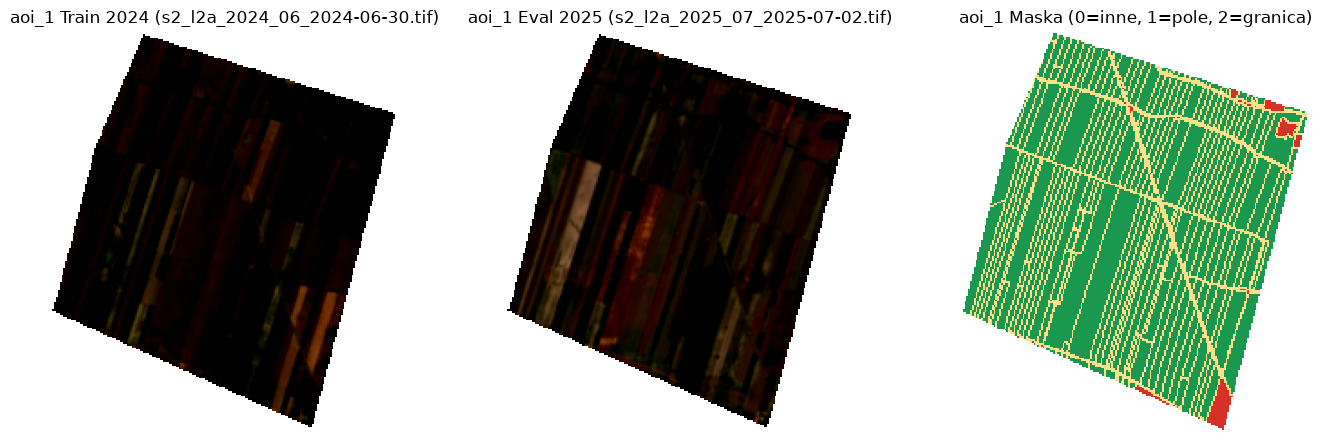

=== aoi_3 | 2024: 25 scen | 2025: 8 scen | maska: True ===


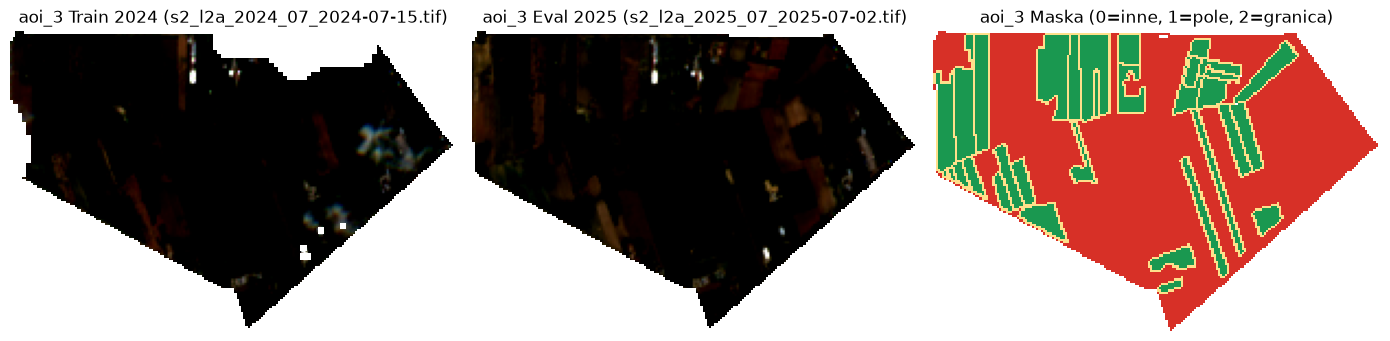

In [6]:
# Weryfikacja i podgląd masek (0=inne, 1=pole, 2=granica_pola) oraz przykładowych scen 2024 / 2025
for cfg in AOI_CONFIGS:
    aoi_dir = OUT_DIR / cfg["name"]
    t24 = sorted(aoi_dir.glob("s2_l2a_2024_*.tif"))
    t25 = sorted(aoi_dir.glob("s2_l2a_2025_*.tif"))
    mask_path = aoi_dir / "label_mask.tif"
    print(f"=== {cfg['name']} | 2024: {len(t24)} scen | 2025: {len(t25)} scen | maska: {mask_path.exists()} ===")
    if not (t24 or t25) or not mask_path.exists():
        continue

    sample_24 = t24[len(t24) // 2] if t24 else t25[0]
    sample_25 = t25[len(t25) // 2] if t25 else sample_24
    with rasterio.open(sample_24) as s24, rasterio.open(sample_25) as s25, rasterio.open(mask_path) as sm:
        rgb24 = np.clip(np.moveaxis(s24.read([1, 2, 3]), 0, -1) / 0.30, 0.0, 1.0)
        rgb25 = np.clip(np.moveaxis(s25.read([1, 2, 3]), 0, -1) / 0.30, 0.0, 1.0)
        gt = sm.read(1)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
    axes[0].imshow(rgb24)
    axes[0].set_title(f"{cfg['name']} Train 2024 ({sample_24.name})")
    axes[1].imshow(rgb25)
    axes[1].set_title(f"{cfg['name']} Eval 2025 ({sample_25.name})")
    axes[2].imshow(np.where(gt == IGNORE_VALUE, np.nan, gt.astype(float)), cmap=ListedColormap(["#d73027", "#1a9850", "#fee08b"]), vmin=0, vmax=2, interpolation="nearest")
    axes[2].set_title(f"{cfg['name']} Maska (0=inne, 1=pole, 2=granica)")
    for ax in axes:
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()